In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import models, layers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
num_notes = 50
sequence_length = 30
num_sequences = 1000

np.random.seed(42)

data = np.random.randint(
    0, num_notes,
    size=(num_sequences, sequence_length)
)

print("Data shape:", data.shape)
print(data[:5])


Data shape: (1000, 30)
[[38 28 14 42  7 20 38 18 22 10 10 23 35 39 23  2 21  1 23 43 29 37  1 20
  32 11 21 43 24 48]
 [26 41 27 15 14 46 43  2 36  6 20  8 38 17  3 24 13 49  8 25  1 19 27 46
   6 43  7 46 34 13]
 [16 35 49 39  3  1  5 41  3 28 17 25 43 33  9 35 13 30 47 14  7 13 22 39
  20 15 44 17 46 23]
 [25 24 44 40 28 14 44  0 24  6  8 23  0 43  7 23 10 16  7 34 34 32  4 41
  38 40 27  6  8  7]
 [11 33 32 47 22 23 36 34 43 39 21 26 34  0 34 36 46 13  2  0  4 25 13 38
  26  8 14 14 25 41]]


In [3]:
x_train = data[:, :-1]
y_train = data[:, 1:]

x_train = to_categorical(
    x_train, num_classes=num_notes
)

y_train = to_categorical(
    y_train, num_classes=num_notes
)

print("Input shape:", x_train.shape)
print("Target shape:", y_train.shape)


Input shape: (1000, 29, 50)
Target shape: (1000, 29, 50)


In [4]:
model = models.Sequential()

model.add(layers.Input(
    shape=(sequence_length - 1, num_notes)
))

model.add(layers.Bidirectional(
    layers.LSTM(128, return_sequences=True)
))

model.add(layers.Bidirectional(
    layers.LSTM(128, return_sequences=True)
))

model.add(layers.TimeDistributed(
    layers.Dense(num_notes, activation='softmax')
))

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")


Model compiled successfully!


In [6]:
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 378ms/step - accuracy: 0.1214 - loss: 3.8837 - val_accuracy: 0.1952 - val_loss: 3.8429
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 481ms/step - accuracy: 0.1635 - loss: 3.7693 - val_accuracy: 0.1122 - val_loss: 3.6524
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 302ms/step - accuracy: 0.1237 - loss: 3.5086 - val_accuracy: 0.1369 - val_loss: 3.3908
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 296ms/step - accuracy: 0.1608 - loss: 3.2237 - val_accuracy: 0.1810 - val_loss: 3.1086
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 434ms/step - accuracy: 0.2097 - loss: 2.8823 - val_accuracy: 0.2352 - val_loss: 2.7251
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 289ms/step - accuracy: 0.2694 - loss: 2.4960 - val_accuracy: 0.3010 - val_loss: 2.3421
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 312ms/step - accuracy: 0.3412 - loss: 2.1102 - val_accuracy: 0.3879 - val_loss: 1.9619
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 393ms/step - accuracy: 0.4296 - loss: 1.7506 - val_accuracy: 0

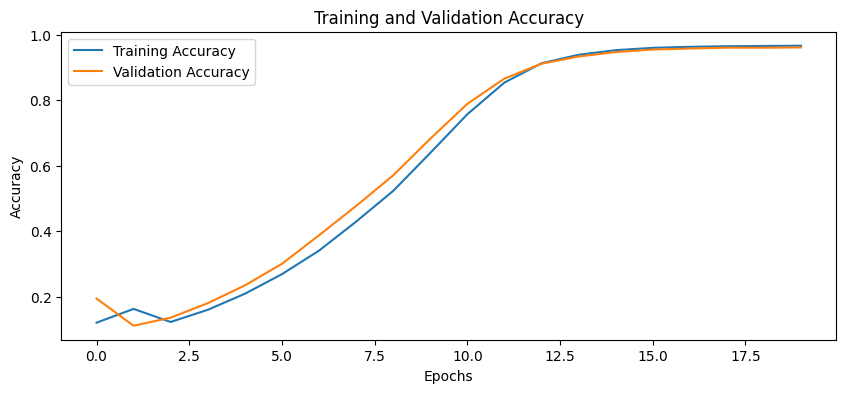

In [7]:
plt.figure(figsize=(10, 4))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


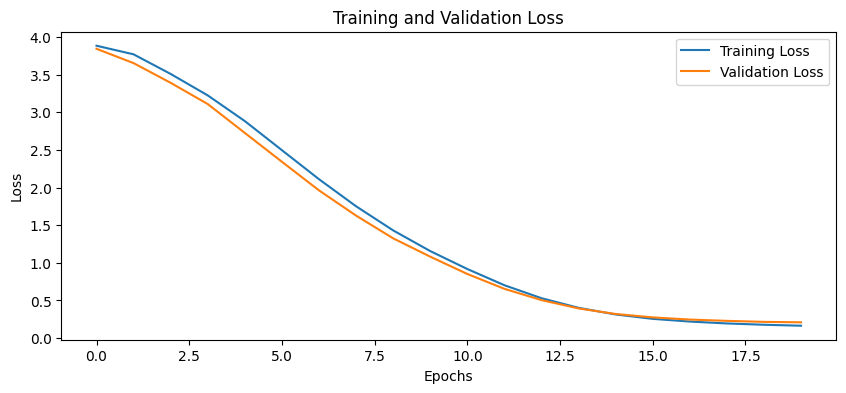

In [8]:
plt.figure(figsize=(10, 4))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [9]:
def generate_music(model, start_sequence,
                   num_generated_notes=50):

    generated = []
    current = start_sequence.copy()

    for _ in range(num_generated_notes):

        pred = model.predict(current, verbose=0)

        next_note = np.argmax(
            pred[:, -1, :], axis=-1
        )

        generated.append(next_note[0])

        oh = to_categorical(
            next_note,
            num_classes=num_notes
        ).reshape(1, 1, num_notes)

        current = np.concatenate(
            [current[:, 1:, :], oh],
            axis=1
        )

    return generated


In [10]:
start_sequence = x_train[0:1]

generated_notes = generate_music(
    model,
    start_sequence,
    num_generated_notes=50
)

print("Generated Music Notes:")
print(generated_notes)


Generated Music Notes:
[np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24)]


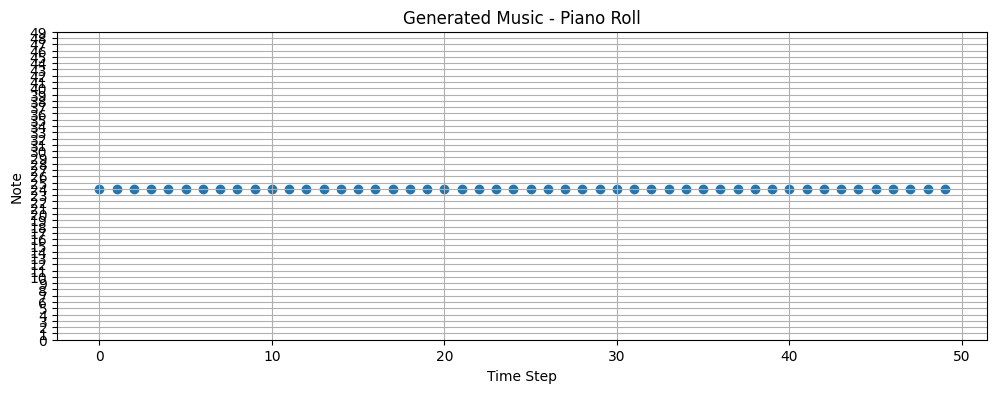

In [11]:
plt.figure(figsize=(12, 4))

plt.scatter(
    range(len(generated_notes)),
    generated_notes
)

plt.title("Generated Music - Piano Roll")
plt.xlabel("Time Step")
plt.ylabel("Note")

plt.yticks(range(num_notes))
plt.grid(True)
plt.show()


Assessment

In [12]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, TimeDistributed

np.random.seed(7)
tf.random.set_seed(7)

num_notes = 40
sequence_length = 25
num_sequences = 1200

data = np.random.randint(
    0, num_notes,
    size=(num_sequences, sequence_length)
)

print("Dataset shape:", data.shape)

Dataset shape: (1200, 25)


In [13]:
x_train = data[:, :-1]
y_train = data[:, 1:]

x_train = to_categorical(x_train, num_classes=40)
y_train = to_categorical(y_train, num_classes=40)

print("X_train shape:", x_train.shape)
print("Y_train shape:", y_train.shape)

X_train shape: (1200, 24, 40)
Y_train shape: (1200, 24, 40)


In [15]:
model = Sequential([
    Input(shape=(24, 40)),

    Bidirectional(
        LSTM(100, return_sequences=True)
    ),

    Bidirectional(
        LSTM(100, return_sequences=True)
    ),

    TimeDistributed(
        Dense(40, activation='softmax')
    )
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_4 (Bidirectional) │ (None, 24, 200)        │       112,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 24, 200)        │       240,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 24, 40)         │         8,040 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,640 (1.38 MB)

 Trainable params: 361,640 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 225ms/step - accuracy: 0.1250 - loss: 3.6569 - val_accuracy: 0.1856 - val_loss: 3.6156
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.1559 - loss: 3.5302 - val_accuracy: 0.1198 - val_loss: 3.4078
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 205ms/step - accuracy: 0.1426 - loss: 3.2588 - val_accuracy: 0.1655 - val_loss: 3.1249
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 241ms/step - accuracy: 0.1840 - loss: 2.9706 - val_accuracy: 0.2059 - val_loss: 2.8249
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 183ms/step - accuracy: 0.2461 - loss: 2.6143 - val_accuracy: 0.2757 - val_loss: 2.4505
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 185ms/step - accuracy: 0.3184 - loss: 2.2250 - val_accuracy: 0.3523 - val_loss: 2.0789
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 189ms/step - accuracy: 0.4013 - loss: 1.8567 - val_accuracy: 0.4372 - val_loss: 1.7218
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 185ms/step - accuracy: 0.4980 - loss: 1.5227 - val_accuracy: 0

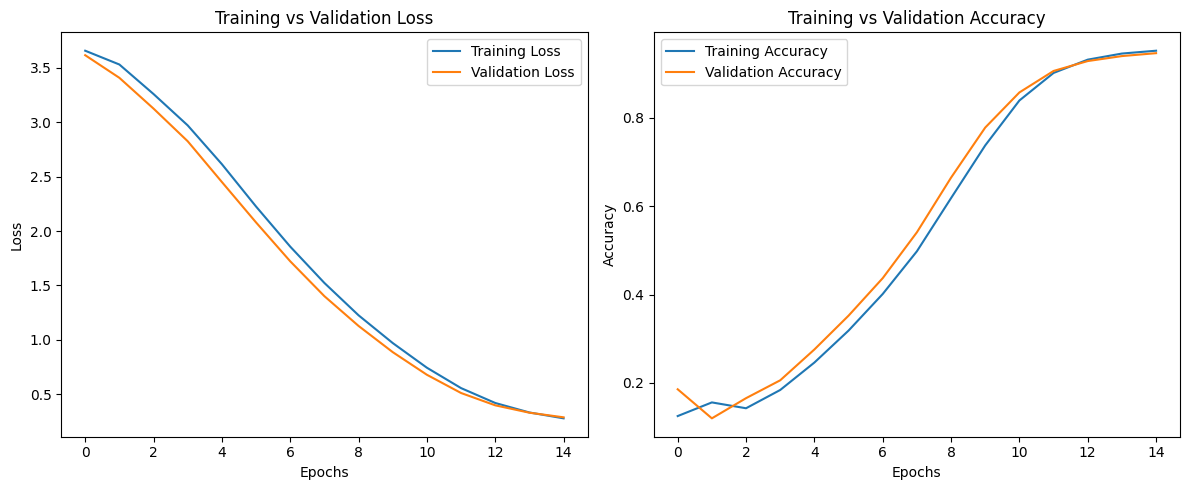

In [17]:
plt.figure(figsize=(12, 5))

# Loss graph
plt.subplot(1, 2, 1)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy graph
plt.subplot(1, 2, 2)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
def generate_music(model, start_sequence, num_generated_notes=40):

    current = start_sequence.copy()
    generated_notes = []

    for i in range(num_generated_notes):

        # Predict the next note
        pred = model.predict(current, verbose=0)

        # Select the last time-step prediction
        next_note = np.argmax(pred[:, -1, :], axis=-1)

        # Store generated note
        generated_notes.append(int(next_note[0]))

        # Convert predicted note into one-hot encoding
        new_note_one_hot = to_categorical(
            next_note,
            num_classes=40
        ).reshape(1, 1, 40)

        # Slide the input window
        current = np.concatenate(
            [current[:, 1:, :], new_note_one_hot],
            axis=1
        )

    return generated_notes


# Create random starting sequence
start_sequence = np.random.randint(0, 40, size=(1, 24))

start_sequence = to_categorical(
    start_sequence,
    num_classes=40
)

# Generate 40 notes
generated = generate_music(
    model,
    start_sequence,
    num_generated_notes=40
)

print("Generated music sequence:")
print(generated)

Generated music sequence:
[26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26]


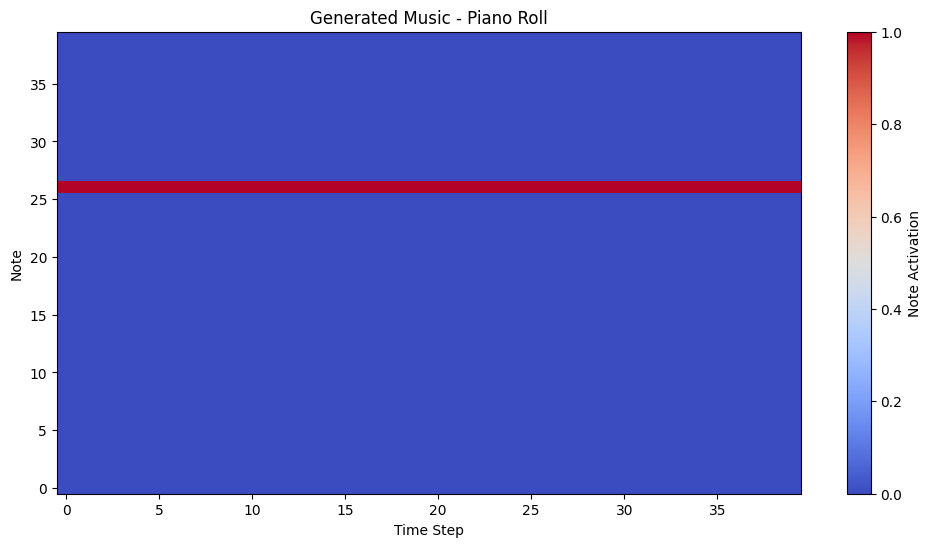

In [19]:
piano_roll = np.zeros((40, 40))

for t, note in enumerate(generated):
    piano_roll[note, t] = 1

plt.figure(figsize=(12, 6))

plt.imshow(
    piano_roll,
    aspect='auto',
    cmap='coolwarm',
    origin='lower'
)

plt.title("Generated Music - Piano Roll")
plt.xlabel("Time Step")
plt.ylabel("Note")

plt.colorbar(label="Note Activation")

plt.show()

The bidirectional LSTM achieves high accuracy because the
backward direction can see the next note in the input sequence,
causing label leakage instead of learning actual musical patterns.